# 2. Preprocessing: from cumulative readings to consumption

The meters report a cumulative counter, so consumption has to be derived from the difference
between readings. Because the readings are irregular (notebook 1), they are first aligned to a
regular 15-min grid.

**Method.** The cumulative volume is interpolated linearly in time at every 15-min boundary,
**but only when the boundary lies between two readings at most 60 min apart**. The consumption
of an interval is the difference of the volume at its two boundaries. Intervals that touch a
longer gap are left empty (NaN): the volume recorded across the gap is real, but its timing is
unknown, so it is not assigned to any hour of the day.

Flow rate (L/s) = consumption of the interval (L) / 900 s.

Each 15-min interval is then labelled with:

* **public holidays** of Panama (`holidays` package),
* **academic period** (classes / vacation) from the university calendar,
* **operating period** of the cafeteria (night, morning preparation, morning service, afternoon
  preparation, evening service, closed). `CAF_CENTRAL` only serves breakfast and lunch, so it
  is labelled closed after 13:30.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

import eda_utils as u

u.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

## 2.1 Why the gap limit matters

An unlimited interpolation spreads the volume of a multi-day gap evenly over every 15-min
interval of the gap, including nights and weekends. The figure below shows one such gap in
`CAF_C1`: the unlimited version invents a constant flow for several days, while the limited
version leaves those intervals empty.

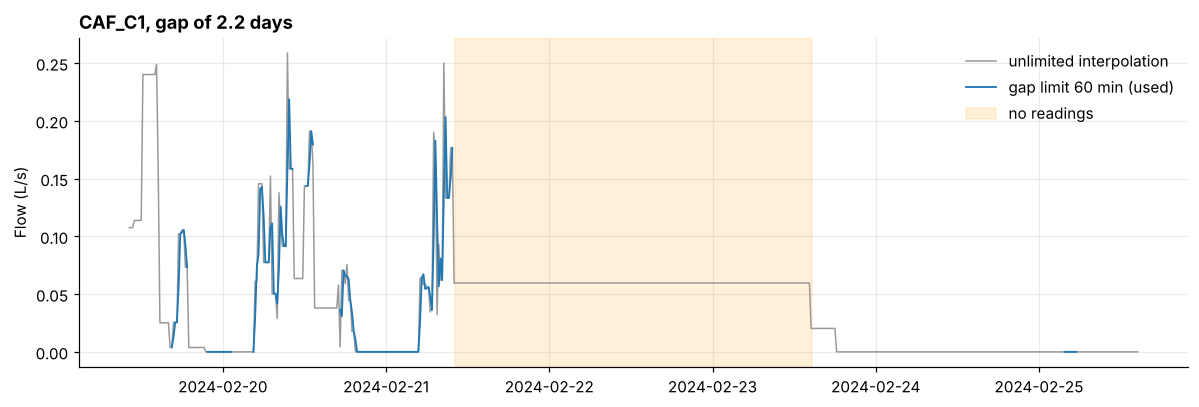

In [2]:
r = u.load_readings("CAF_C1")
limited = u.consumption_15min(r) / u.BIN_SECONDS
unlimited = u.consumption_15min_unlimited(r) / u.BIN_SECONDS

dt = u.sampling_intervals(r)
gap_end = dt[(dt > 2 * 1440) & (dt < 6 * 1440)].index[0]
gap_start = gap_end - pd.Timedelta(minutes=dt[gap_end])
window = slice(gap_start - pd.Timedelta("2D"), gap_end + pd.Timedelta("2D"))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(unlimited[window], color="0.6", lw=1, label="unlimited interpolation")
ax.plot(limited[window], color=u.COLORS["CAF_C1"], lw=1.2, label="gap limit 60 min (used)")
ax.axvspan(gap_start, gap_end, color="orange", alpha=0.15, label="no readings")
ax.set_ylabel("Flow (L/s)")
ax.set_title(f"CAF_C1, gap of {dt[gap_end] / 1440:.1f} days", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()
u.savefig(fig, "02_gap_example")

## 2.2 Sensitivity to the gap limit

Share of 15-min intervals with a valid consumption value for different gap limits. 60 min keeps
most of the data of `CAF_CENTRAL` and `CAF_C3`; a longer limit adds little and starts to spread
consumption over several hours.

In [3]:
pd.DataFrame({
    f"≤ {g} min": {caf: u.consumption_15min(u.load_readings(caf), g).notna().mean() * 100
                   for caf in u.CAFETERIAS}
    for g in [15, 30, 60, 120, 240]
}).round(1)

,≤ 15 min,≤ 30 min,≤ 60 min,≤ 120 min,≤ 240 min
CAF_C1,2.400,5.300,8.700,12.500,16.200
CAF_CENTRAL,52.300,78.600,89.000,90.400,90.900
CAF_C3,39.400,64.400,76.900,80.200,82.500


## 2.3 Labelled 15-min dataset

In [4]:
df = u.build_dataset()
df.head()

,consumption_L,flow_Ls,cafeteria,date,hour,day_name,is_weekday,is_holiday,academic_period,operating_period,day_type
datetime,,,,,,,,,,,
2023-10-29 23:45:00,0.000,0.000,CAF_C1,2023-10-29,23,Sunday,False,False,classes,closed,weekend
2023-10-30 00:00:00,0.000,0.000,CAF_C1,2023-10-30,0,Monday,True,False,classes,night,weekday
2023-10-30 00:15:00,0.000,0.000,CAF_C1,2023-10-30,0,Monday,True,False,classes,night,weekday
2023-10-30 00:30:00,0.000,0.000,CAF_C1,2023-10-30,0,Monday,True,False,classes,night,weekday
2023-10-30 00:45:00,0.000,0.000,CAF_C1,2023-10-30,0,Monday,True,False,classes,night,weekday


In [5]:
summary = df.groupby("cafeteria").agg(
    intervals=("consumption_L", "size"),
    valid=("consumption_L", "count"),
    total_m3=("consumption_L", lambda s: s.sum() / 1000),
)
summary["valid (%)"] = summary["valid"] / summary["intervals"] * 100
summary

,intervals,valid,total_m3,valid (%)
cafeteria,,,,
CAF_C1,58118,5065,141.709,8.715
CAF_C3,65449,50328,587.162,76.897
CAF_CENTRAL,65447,58264,375.200,89.025


In [6]:
pd.crosstab(df["cafeteria"], df["academic_period"], values=df["consumption_L"], aggfunc="count")

academic_period,classes,vacation
cafeteria,,
CAF_C1,4473,592
CAF_C3,43631,6697
CAF_CENTRAL,48773,9491


## 2.4 Checks: negative values and peaks

No interval has negative consumption (the counters never decreased). Peaks are **not**
clipped; they are only counted here so that they can be inspected.

In [7]:
valid = df.dropna(subset=["consumption_L"])
checks = valid.groupby("cafeteria")["flow_Ls"].agg(
    negative=lambda s: int((s < 0).sum()),
    p99="quantile",
    maximum="max",
)
checks["p99"] = valid.groupby("cafeteria")["flow_Ls"].quantile(0.99)
checks["intervals > 1 L/s"] = valid.groupby("cafeteria")["flow_Ls"].apply(lambda s: int((s > 1).sum()))
checks

,negative,p99,maximum,intervals > 1 L/s
cafeteria,,,,
CAF_C1,0,0.249,0.386,0
CAF_C3,0,0.124,0.356,0
CAF_CENTRAL,0,0.103,0.287,0


## Observations

* With the 60-min gap limit, a valid consumption value is available for 89 % of the 15-min
  intervals of `CAF_CENTRAL`, 77 % of `CAF_C3` and only 9 % of `CAF_C1`.
* Interpolating without a limit would fill the long gaps with a constant, invented flow, which
  shows up as consumption at night and on weekends (figure in 2.1). This matters most for
  `CAF_C1`.
* No interval has negative consumption, and the largest 15-min flows (0.29–0.39 L/s) are
  plausible, so no values were removed or clipped.